In [ ]:
import pandas as pd
import numpy as np
import json
import os
import glob
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ipl_json.zip to ipl_json.zip


In [ ]:
import zipfile
import os

zip_name = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall('/content/ipl_data')

print("Files extracted successfully!")

Files extracted successfully!


In [ ]:
json_files = glob.glob(
    '/content/ipl_data/**/*.json',
    recursive=True
)

print("Total JSON files:", len(json_files))
print(json_files[:5])

Total JSON files: 1243
['/content/ipl_data/1304053.json', '/content/ipl_data/829707.json', '/content/ipl_data/335985.json', '/content/ipl_data/392212.json', '/content/ipl_data/1136582.json']


In [ ]:
import json
import glob
import pandas as pd
import numpy as np

match_records = []

for file in json_files:

    try:
        with open(file, 'r') as f:
            data = json.load(f)

        info = data.get('info', {})

        # Filter men's IPL T20 matches
        event = info.get('event', {})
        event_name = str(event.get('name', '')).lower()

        if 'indian premier league' not in event_name:
            continue

        if info.get('gender') != 'male':
            continue

        if info.get('match_type') != 'T20':
            continue

        innings = data.get('innings', [])

        # Exclude super-over innings
        regulation_innings = [
            inn for inn in innings
            if not inn.get('super_over', False)
        ][:2]

        if len(regulation_innings) < 2:
            continue

        # First innings
        first = regulation_innings[0]
        second = regulation_innings[1]

        first_team = first.get('team')
        second_team = second.get('team')

        def calculate_score(inn):
            score = 0

            for over in inn.get('overs', []):
                for delivery in over.get('deliveries', []):
                    score += delivery.get('runs', {}).get(
                        'total', 0
                    )

            # Include any innings penalty runs
            penalties = inn.get('penalty_runs', {})
            score += penalties.get('pre', 0)
            score += penalties.get('post', 0)

            return score

        first_score = calculate_score(first)
        second_score = calculate_score(second)

        outcome = info.get('outcome', {})

        winner = outcome.get('winner')

        # Resolve super-over winners where recorded as eliminator
        if not winner:
            winner = outcome.get('eliminator')

        toss = info.get('toss', {})

        match_records.append({
            'match_id': os.path.basename(file).replace(
                '.json', ''
            ),
            'season': info.get('season'),
            'date': info.get('dates', [None])[0],
            'venue': info.get('venue'),
            'city': info.get('city'),
            'team1': info.get('teams', [None, None])[0],
            'team2': info.get('teams', [None, None])[1],
            'toss_winner': toss.get('winner'),
            'toss_decision': toss.get('decision'),
            'batting_first': first_team,
            'batting_second': second_team,
            'first_innings_score': first_score,
            'second_innings_score': second_score,
            'winner': winner,
            'result': outcome.get('result'),
            'method': outcome.get('method'),
            'match_timing': 'Unknown'
        })

    except Exception as e:
        print("Error:", file, e)

matches = pd.DataFrame(match_records)

print("Total IPL matches:", len(matches))
matches.head()

Total IPL matches: 1237


,match_id,season,date,venue,city,team1,team2,toss_winner,toss_decision,batting_first,batting_second,first_innings_score,second_innings_score,winner,result,method,match_timing
0,1304053,2022,2022-03-31,"Brabourne Stadium, Mumbai",Mumbai,Chennai Super Kings,Lucknow Super Giants,Lucknow Super Giants,field,Chennai Super Kings,Lucknow Super Giants,210,211,Lucknow Super Giants,None,None,Unknown
1,829707,2015,2015-04-09,MA Chidambaram Stadium,Chennai,Chennai Super Kings,Delhi Daredevils,Delhi Daredevils,field,Chennai Super Kings,Delhi Daredevils,150,149,Chennai Super Kings,None,None,Unknown
2,335985,2007/08,2008-04-20,"Wankhede Stadium, Mumbai",Mumbai,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Mumbai Indians,Royal Challengers Bangalore,165,166,Royal Challengers Bangalore,None,None,Unknown
3,392212,2009,2009-05-06,"SuperSport Park, Centurion",Centurion,Deccan Chargers,Mumbai Indians,Deccan Chargers,bat,Deccan Chargers,Mumbai Indians,145,126,Deccan Chargers,None,None,Unknown
4,1136582,2018,2018-04-23,"Feroz Shah Kotla, Delhi",Delhi,Kings XI Punjab,Delhi Daredevils,Delhi Daredevils,field,Kings XI Punjab,Delhi Daredevils,143,139,Kings XI Punjab,None,None,Unknown


In [ ]:
print("Dataset shape:", matches.shape)

print("\nMissing values:")
print(matches.isnull().sum())

print("\nDuplicate matches:")
print(matches.duplicated(
    subset=['match_id']
).sum())

Dataset shape: (1237, 17)

Missing values:
match_id                   0
season                     0
date                       0
venue                      0
city                      51
team1                      0
team2                      0
toss_winner                0
toss_decision              0
batting_first              0
batting_second             0
first_innings_score        0
second_innings_score       0
winner                     3
result                  1218
method                  1214
match_timing               0
dtype: int64

Duplicate matches:
0


In [ ]:
# Remove duplicate match IDs
matches = matches.drop_duplicates(
    subset=['match_id']
)

# Remove records without essential information
matches = matches.dropna(
    subset=[
        'venue',
        'batting_first',
        'batting_second',
        'first_innings_score',
        'winner'
    ]
)

# Remove matches without a valid result
matches = matches[
    matches['winner'].isin(
        matches[['batting_first', 'batting_second']].values.flatten()
    )
]

# Convert scores to numeric
matches['first_innings_score'] = pd.to_numeric(
    matches['first_innings_score'],
    errors='coerce'
)

matches = matches.dropna(
    subset=['first_innings_score']
)

# Create win indicators
matches['batting_first_win'] = (
    matches['winner'] == matches['batting_first']
).astype(int)

matches['chasing_win'] = (
    matches['winner'] == matches['batting_second']
).astype(int)

print("Cleaned dataset:", matches.shape)
matches.head()

Cleaned dataset: (1234, 19)


,match_id,season,date,venue,city,team1,team2,toss_winner,toss_decision,batting_first,batting_second,first_innings_score,second_innings_score,winner,result,method,match_timing,batting_first_win,chasing_win
0,1304053,2022,2022-03-31,"Brabourne Stadium, Mumbai",Mumbai,Chennai Super Kings,Lucknow Super Giants,Lucknow Super Giants,field,Chennai Super Kings,Lucknow Super Giants,210,211,Lucknow Super Giants,None,None,Unknown,0,1
1,829707,2015,2015-04-09,MA Chidambaram Stadium,Chennai,Chennai Super Kings,Delhi Daredevils,Delhi Daredevils,field,Chennai Super Kings,Delhi Daredevils,150,149,Chennai Super Kings,None,None,Unknown,1,0
2,335985,2007/08,2008-04-20,"Wankhede Stadium, Mumbai",Mumbai,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Mumbai Indians,Royal Challengers Bangalore,165,166,Royal Challengers Bangalore,None,None,Unknown,0,1
3,392212,2009,2009-05-06,"SuperSport Park, Centurion",Centurion,Deccan Chargers,Mumbai Indians,Deccan Chargers,bat,Deccan Chargers,Mumbai Indians,145,126,Deccan Chargers,None,None,Unknown,1,0
4,1136582,2018,2018-04-23,"Feroz Shah Kotla, Delhi",Delhi,Kings XI Punjab,Delhi Daredevils,Delhi Daredevils,field,Kings XI Punjab,Delhi Daredevils,143,139,Kings XI Punjab,None,None,Unknown,1,0


In [ ]:
venue_analysis = matches.groupby('venue').agg(

    total_matches=('match_id', 'count'),

    batting_first_wins=('batting_first_win', 'sum'),

    chasing_wins=('chasing_win', 'sum'),

    average_first_innings_score=(
        'first_innings_score', 'mean'
    )

).reset_index()

venue_analysis['batting_first_win_rate'] = (
    venue_analysis['batting_first_wins'] /
    venue_analysis['total_matches'] * 100
).round(2)

venue_analysis['chasing_win_rate'] = (
    venue_analysis['chasing_wins'] /
    venue_analysis['total_matches'] * 100
).round(2)

venue_analysis['recommendation'] = np.where(
    venue_analysis['batting_first_win_rate'] >
    venue_analysis['chasing_win_rate'],
    'Bat First',
    np.where(
        venue_analysis['chasing_win_rate'] >
        venue_analysis['batting_first_win_rate'],
        'Bowl First',
        'No Clear Advantage'
    )
)

venue_analysis['reliability'] = pd.cut(
    venue_analysis['total_matches'],
    bins=[0, 9, 19, 29, float('inf')],
    labels=[
        'Very Low',
        'Low',
        'Moderate',
        'Better Sample'
    ]
)

venue_analysis = venue_analysis.sort_values(
    'total_matches',
    ascending=False
)

venue_analysis

,venue,total_matches,batting_first_wins,chasing_wins,average_first_innings_score,batting_first_win_rate,chasing_win_rate,recommendation,reliability
40,"Wankhede Stadium, Mumbai",132,60,72,173.128788,45.45,54.55,Bowl First,Better Sample
10,"Eden Gardens, Kolkata",105,45,60,169.695238,42.86,57.14,Bowl First,Better Sample
19,MA Chidambaram Stadium,98,53,45,165.561224,54.08,45.92,Bat First,Better Sample
28,"Rajiv Gandhi International Stadium, Uppal",89,40,49,168.741573,44.94,55.06,Bowl First,Better Sample
11,"Feroz Shah Kotla, Delhi",73,34,39,164.356164,46.58,53.42,Bowl First,Better Sample
31,"Sawai Mansingh Stadium, Jaipur",68,24,44,169.058824,35.29,64.71,Bowl First,Better Sample
18,"M Chinnaswamy Stadium, Bengaluru",59,27,32,182.152542,45.76,54.24,Bowl First,Better Sample
9,Dubai International Cricket Stadium,46,23,23,163.760870,50.00,50.00,No Clear Advantage,Better Sample
23,"Narendra Modi Stadium, Ahmedabad",45,20,25,183.533333,44.44,55.56,Bowl First,Better Sample
21,"Maharashtra Cricket Association Stadium, Pune",42,22,20,164.785714,52.38,47.62,Bat First,Better Sample


In [ ]:
venue_analysis = matches.groupby('venue').agg(
    total_matches=('match_id', 'count'),
    batting_first_wins=('batting_first_win', 'sum'),
    chasing_wins=('chasing_win', 'sum'),
    avg_first_innings_score=('first_innings_score', 'mean')
).reset_index()

venue_analysis['batting_first_win_pct'] = (
    venue_analysis['batting_first_wins'] /
    venue_analysis['total_matches'] * 100
).round(2)

venue_analysis['chasing_win_pct'] = (
    venue_analysis['chasing_wins'] /
    venue_analysis['total_matches'] * 100
).round(2)

venue_analysis['avg_first_innings_score'] = (
    venue_analysis['avg_first_innings_score'].round(2)
)

venue_analysis = venue_analysis.sort_values(
    'total_matches', ascending=False
)

display(venue_analysis.head(15))

,venue,total_matches,batting_first_wins,chasing_wins,avg_first_innings_score,batting_first_win_pct,chasing_win_pct
39,"Wankhede Stadium, Mumbai",132,60,72,173.13,45.45,54.55
11,"Eden Gardens, Kolkata",105,45,60,169.70,42.86,57.14
17,"M Chinnaswamy Stadium, Bengaluru",101,44,57,174.78,43.56,56.44
18,MA Chidambaram Stadium,98,53,45,165.56,54.08,45.92
27,"Rajiv Gandhi International Stadium, Uppal",89,40,49,168.74,44.94,55.06
2,"Arun Jaitley Stadium, Delhi",73,34,39,164.36,46.58,53.42
30,"Sawai Mansingh Stadium, Jaipur",68,24,44,169.06,35.29,64.71
10,Dubai International Cricket Stadium,46,23,23,163.76,50.00,50.00
22,"Narendra Modi Stadium, Ahmedabad",45,20,25,183.53,44.44,55.56
20,"Maharashtra Cricket Association Stadium, Pune",42,22,20,164.79,52.38,47.62


In [ ]:
matches['venue'] = matches['venue'].replace({
    'M Chinnaswamy Stadium, Bangalore':
    'M Chinnaswamy Stadium, Bengaluru'
})

In [ ]:
venue_analysis['toss_recommendation'] = venue_analysis.apply(
    lambda row: 'Bat First'
    if row['batting_first_win_pct'] > row['chasing_win_pct']
    else 'Bowl First'
    if row['chasing_win_pct'] > row['batting_first_win_pct']
    else 'No Clear Advantage',
    axis=1
)

venue_analysis['sample_reliability'] = pd.cut(
    venue_analysis['total_matches'],
    bins=[0, 9, 19, 29, float('inf')],
    labels=['Very Low', 'Low', 'Moderate', 'Better Sample']
)

display(
    venue_analysis.sort_values(
        'total_matches', ascending=False
    ).head(15)
)

,venue,total_matches,batting_first_wins,chasing_wins,avg_first_innings_score,batting_first_win_pct,chasing_win_pct,toss_recommendation,sample_reliability
39,"Wankhede Stadium, Mumbai",132,60,72,173.128788,45.45,54.55,Bowl First,Better Sample
10,"Eden Gardens, Kolkata",105,45,60,169.695238,42.86,57.14,Bowl First,Better Sample
17,"M Chinnaswamy Stadium, Bengaluru",101,44,57,174.782178,43.56,56.44,Bowl First,Better Sample
18,MA Chidambaram Stadium,98,53,45,165.561224,54.08,45.92,Bat First,Better Sample
27,"Rajiv Gandhi International Stadium, Uppal",89,40,49,168.741573,44.94,55.06,Bowl First,Better Sample
11,"Feroz Shah Kotla, Delhi",73,34,39,164.356164,46.58,53.42,Bowl First,Better Sample
30,"Sawai Mansingh Stadium, Jaipur",68,24,44,169.058824,35.29,64.71,Bowl First,Better Sample
9,Dubai International Cricket Stadium,46,23,23,163.760870,50.00,50.00,No Clear Advantage,Better Sample
22,"Narendra Modi Stadium, Ahmedabad",45,20,25,183.533333,44.44,55.56,Bowl First,Better Sample
20,"Maharashtra Cricket Association Stadium, Pune",42,22,20,164.785714,52.38,47.62,Bat First,Better Sample


In [ ]:
# Remove extra spaces from venue names
matches['venue'] = matches['venue'].str.strip()

# Standardize Bangalore and Bengaluru naming
matches['venue'] = matches['venue'].str.replace(
    'M Chinnaswamy Stadium, Bangalore',
    'M Chinnaswamy Stadium, Bengaluru',
    regex=False
)

In [ ]:
venue_analysis = matches.groupby('venue').agg(
    total_matches=('match_id', 'count'),
    batting_first_wins=('batting_first_win', 'sum'),
    chasing_wins=('chasing_win', 'sum'),
    avg_first_innings_score=('first_innings_score', 'mean')
).reset_index()

venue_analysis['batting_first_win_pct'] = (
    venue_analysis['batting_first_wins'] /
    venue_analysis['total_matches'] * 100
).round(2)

venue_analysis['chasing_win_pct'] = (
    venue_analysis['chasing_wins'] /
    venue_analysis['total_matches'] * 100
).round(2)

venue_analysis['toss_recommendation'] = venue_analysis.apply(
    lambda row: 'Bat First'
    if row['batting_first_win_pct'] > row['chasing_win_pct']
    else 'Bowl First'
    if row['chasing_win_pct'] > row['batting_first_win_pct']
    else 'No Clear Advantage',
    axis=1
)

venue_analysis['sample_reliability'] = pd.cut(
    venue_analysis['total_matches'],
    bins=[0, 9, 19, 29, float('inf')],
    labels=['Very Low', 'Low', 'Moderate', 'Better Sample']
)

venue_analysis = venue_analysis.sort_values(
    'total_matches', ascending=False
)

display(venue_analysis.head(15))

,venue,total_matches,batting_first_wins,chasing_wins,avg_first_innings_score,batting_first_win_pct,chasing_win_pct,toss_recommendation,sample_reliability
39,"Wankhede Stadium, Mumbai",132,60,72,173.128788,45.45,54.55,Bowl First,Better Sample
10,"Eden Gardens, Kolkata",105,45,60,169.695238,42.86,57.14,Bowl First,Better Sample
17,"M Chinnaswamy Stadium, Bengaluru",101,44,57,174.782178,43.56,56.44,Bowl First,Better Sample
18,MA Chidambaram Stadium,98,53,45,165.561224,54.08,45.92,Bat First,Better Sample
27,"Rajiv Gandhi International Stadium, Uppal",89,40,49,168.741573,44.94,55.06,Bowl First,Better Sample
11,"Feroz Shah Kotla, Delhi",73,34,39,164.356164,46.58,53.42,Bowl First,Better Sample
30,"Sawai Mansingh Stadium, Jaipur",68,24,44,169.058824,35.29,64.71,Bowl First,Better Sample
9,Dubai International Cricket Stadium,46,23,23,163.760870,50.00,50.00,No Clear Advantage,Better Sample
22,"Narendra Modi Stadium, Ahmedabad",45,20,25,183.533333,44.44,55.56,Bowl First,Better Sample
20,"Maharashtra Cricket Association Stadium, Pune",42,22,20,164.785714,52.38,47.62,Bat First,Better Sample


In [ ]:
matches['venue'] = matches['venue'].replace({
    'Feroz Shah Kotla, Delhi':
    'Arun Jaitley Stadium, Delhi',

    'Punjab Cricket Association Stadium, Mohali, Chandigarh':
    'Punjab Cricket Association IS Bindra Stadium, Mohali'
})

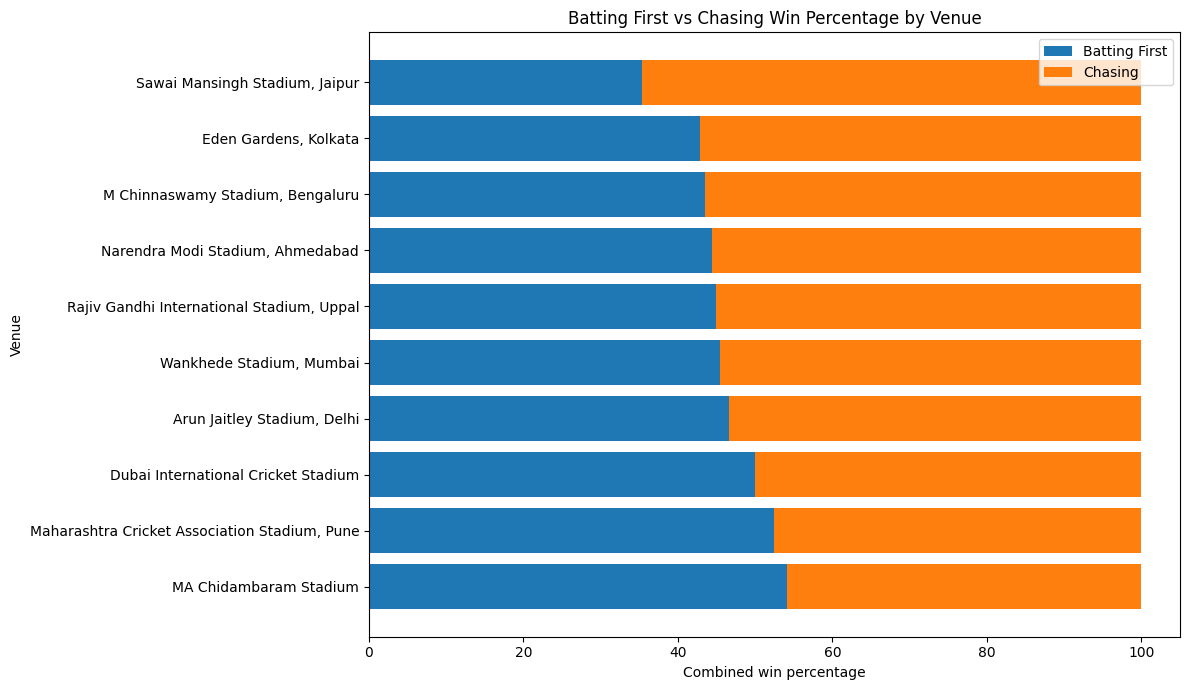

In [ ]:
import matplotlib.pyplot as plt

top_venues = venue_analysis.head(10).sort_values(
    'chasing_win_pct'
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_venues['venue'],
    top_venues['batting_first_win_pct'],
    label='Batting First'
)

plt.barh(
    top_venues['venue'],
    top_venues['chasing_win_pct'],
    left=top_venues['batting_first_win_pct'],
    label='Chasing'
)

plt.xlabel('Combined win percentage')
plt.ylabel('Venue')
plt.title('Batting First vs Chasing Win Percentage by Venue')
plt.legend()
plt.tight_layout()
plt.show()

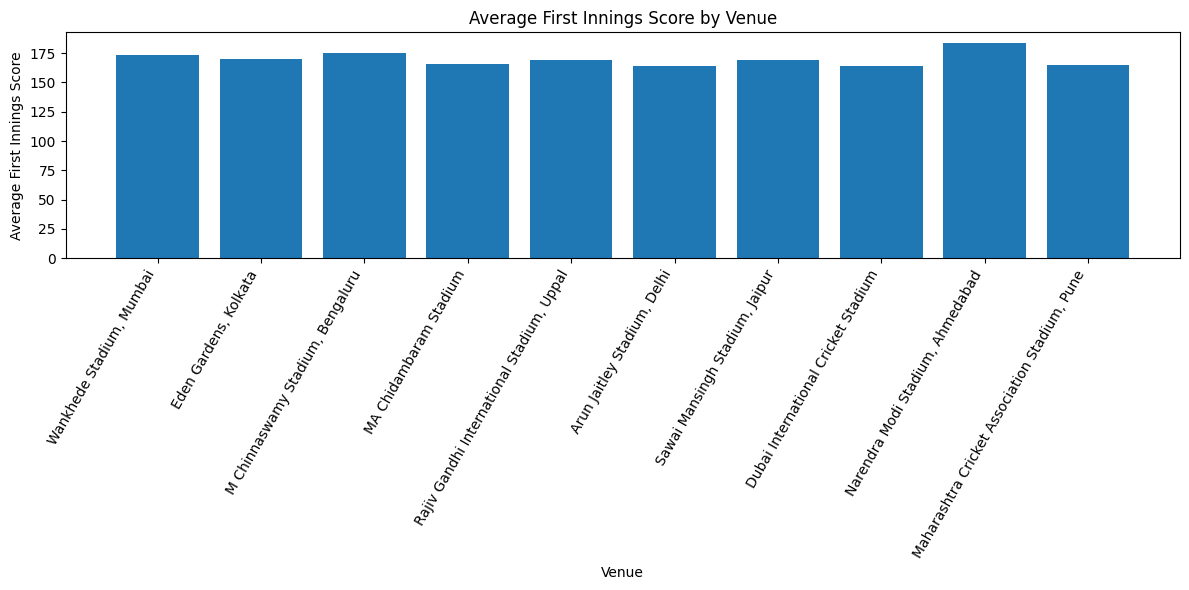

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(
    venue_analysis.head(10)['venue'],
    venue_analysis.head(10)['avg_first_innings_score']
)

plt.title('Average First Innings Score by Venue')
plt.xlabel('Venue')
plt.ylabel('Average First Innings Score')

plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
venue_analysis.to_csv(
    'IPL_Venue_Analysis.csv',
    index=False
)

matches.to_csv(
    'IPL_Match_Level_Data.csv',
    index=False
)

from google.colab import files

files.download('IPL_Venue_Analysis.csv')
files.download('IPL_Match_Level_Data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def standardize_venue(venue):
    venue = str(venue).strip()

    if 'arun jaitley' in venue.lower() or 'feroz shah kotla' in venue.lower():
        return 'Arun Jaitley Stadium, Delhi'

    if 'punjab cricket association' in venue.lower() and 'mohali' in venue.lower():
        return 'Punjab Cricket Association IS Bindra Stadium, Mohali'

    return venue

matches['venue'] = matches['venue'].apply(standardize_venue)

In [ ]:
venue_analysis = matches.groupby('venue').agg(
    total_matches=('match_id', 'count'),
    batting_first_wins=('batting_first_win', 'sum'),
    chasing_wins=('chasing_win', 'sum'),
    avg_first_innings_score=('first_innings_score', 'mean')
).reset_index()

venue_analysis['batting_first_win_pct'] = (
    venue_analysis['batting_first_wins'] /
    venue_analysis['total_matches'] * 100
).round(2)

venue_analysis['chasing_win_pct'] = (
    venue_analysis['chasing_wins'] /
    venue_analysis['total_matches'] * 100
).round(2)

venue_analysis['avg_first_innings_score'] = (
    venue_analysis['avg_first_innings_score'].round(2)
)

venue_analysis['toss_recommendation'] = venue_analysis.apply(
    lambda row: 'Bat First'
    if row['batting_first_win_pct'] > row['chasing_win_pct']
    else 'Bowl First'
    if row['chasing_win_pct'] > row['batting_first_win_pct']
    else 'No Clear Advantage',
    axis=1
)

venue_analysis['sample_reliability'] = pd.cut(
    venue_analysis['total_matches'],
    bins=[0, 9, 19, 29, float('inf')],
    labels=['Very Low', 'Low', 'Moderate', 'Better Sample']
)

venue_analysis = venue_analysis.sort_values(
    'total_matches', ascending=False
)

display(venue_analysis.head(15))

,venue,total_matches,batting_first_wins,chasing_wins,avg_first_innings_score,batting_first_win_pct,chasing_win_pct,toss_recommendation,sample_reliability
37,"Wankhede Stadium, Mumbai",132,60,72,173.13,45.45,54.55,Bowl First,Better Sample
10,"Eden Gardens, Kolkata",105,45,60,169.70,42.86,57.14,Bowl First,Better Sample
1,"Arun Jaitley Stadium, Delhi",103,48,55,172.88,46.60,53.40,Bowl First,Better Sample
16,"M Chinnaswamy Stadium, Bengaluru",101,44,57,174.78,43.56,56.44,Bowl First,Better Sample
17,MA Chidambaram Stadium,98,53,45,165.56,54.08,45.92,Bat First,Better Sample
25,"Rajiv Gandhi International Stadium, Uppal",89,40,49,168.74,44.94,55.06,Bowl First,Better Sample
28,"Sawai Mansingh Stadium, Jaipur",68,24,44,169.06,35.29,64.71,Bowl First,Better Sample
24,"Punjab Cricket Association IS Bindra Stadium, ...",61,27,34,168.28,44.26,55.74,Bowl First,Better Sample
9,Dubai International Cricket Stadium,46,23,23,163.76,50.00,50.00,No Clear Advantage,Better Sample
21,"Narendra Modi Stadium, Ahmedabad",45,20,25,183.53,44.44,55.56,Bowl First,Better Sample


In [ ]:
print(
    venue_analysis[
        venue_analysis['venue'].str.contains(
            'Delhi|Mohali', case=False, na=False
        )
    ].to_string(index=False)
)

                                               venue  total_matches  batting_first_wins  chasing_wins  avg_first_innings_score  batting_first_win_pct  chasing_win_pct toss_recommendation sample_reliability
                         Arun Jaitley Stadium, Delhi            103                  48            55                   172.88                  46.60            53.40          Bowl First      Better Sample
Punjab Cricket Association IS Bindra Stadium, Mohali             61                  27            34                   168.28                  44.26            55.74          Bowl First      Better Sample


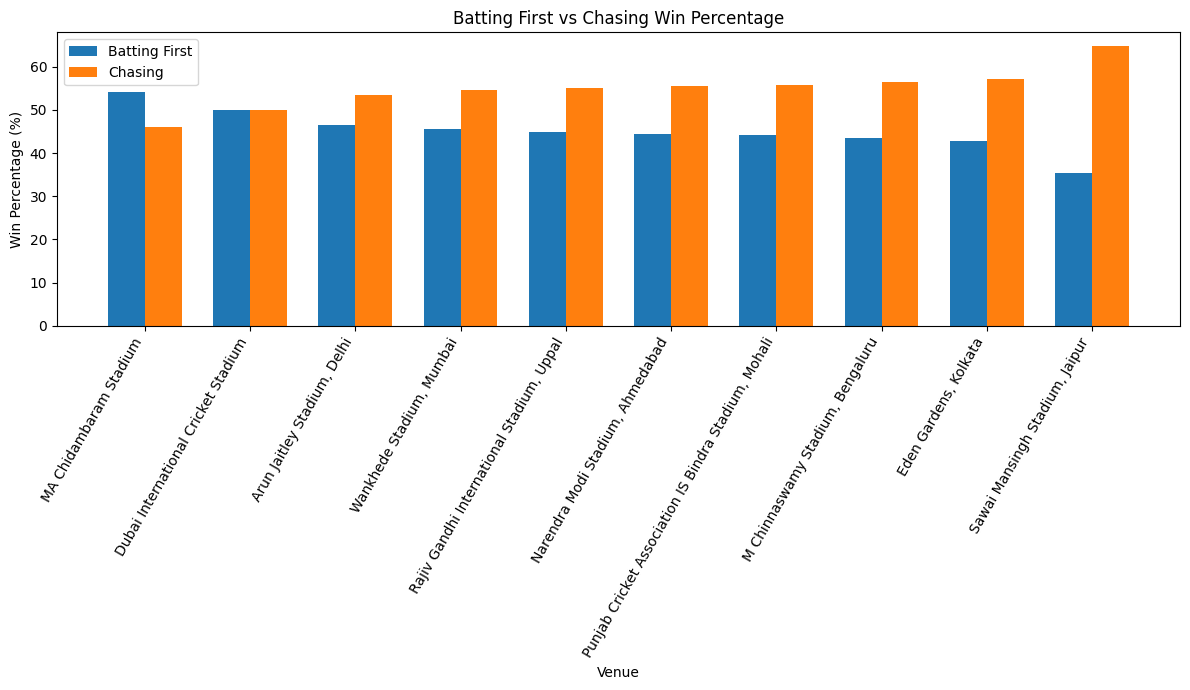

In [ ]:
import matplotlib.pyplot as plt

top_10 = venue_analysis.head(10).sort_values(
    'chasing_win_pct'
)

plt.figure(figsize=(12, 7))

x = range(len(top_10))
width = 0.35

plt.bar(
    [i - width/2 for i in x],
    top_10['batting_first_win_pct'],
    width,
    label='Batting First'
)

plt.bar(
    [i + width/2 for i in x],
    top_10['chasing_win_pct'],
    width,
    label='Chasing'
)

plt.xticks(
    list(x),
    top_10['venue'],
    rotation=60,
    ha='right'
)

plt.ylabel('Win Percentage (%)')
plt.xlabel('Venue')
plt.title('Batting First vs Chasing Win Percentage')
plt.legend()
plt.tight_layout()
plt.show()

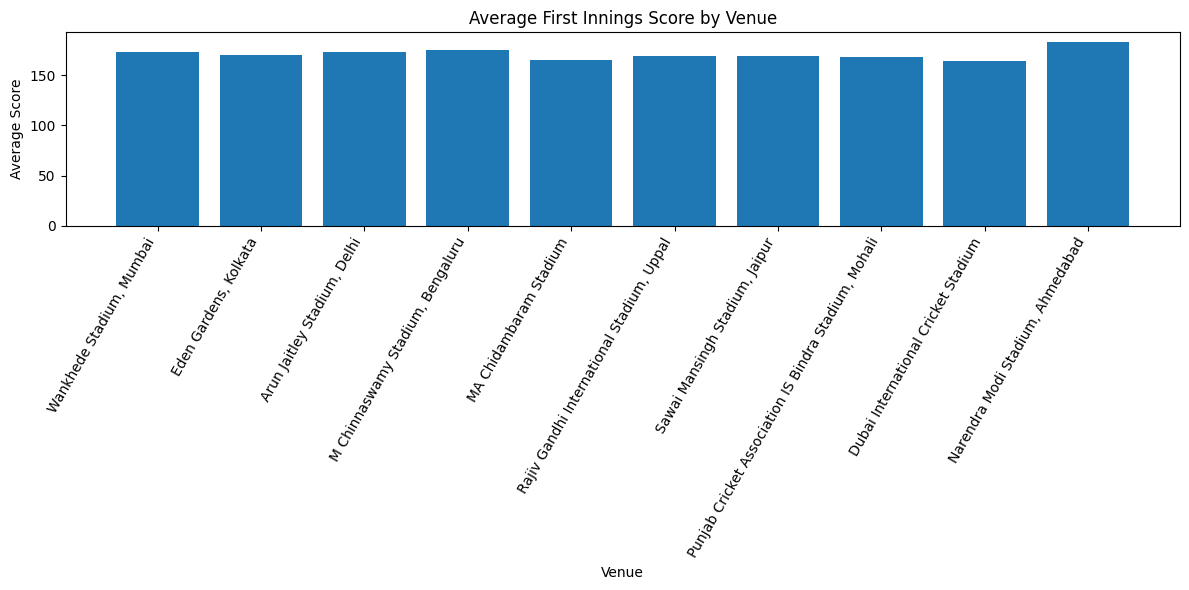

In [ ]:
plt.figure(figsize=(12, 6))

scores = venue_analysis.head(10)

plt.bar(
    scores['venue'],
    scores['avg_first_innings_score']
)

plt.title('Average First Innings Score by Venue')
plt.xlabel('Venue')
plt.ylabel('Average Score')

plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
matches.to_csv('IPL_Match_Level_Data.csv', index=False)

venue_analysis.to_csv('IPL_Venue_Analysis.csv', index=False)

from google.colab import files

files.download('IPL_Match_Level_Data.csv')
files.download('IPL_Venue_Analysis.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>